# Guía 6 — Parte III: Ecuaciones de Maxwell, principio de acción y gauge

**Electromagnetismo Intermedio · Universidad de Valparaíso · 2026**

Problemas **9–14**. Esta parte es más estructural que geométrica, así que combinamos tres tipos de "simulación":

1. **Álgebra simbólica (SymPy)**: dejamos que la computadora haga *todas* las sumas sobre índices. Así comprobamos las Partes 9–11 sin errores de signo y con potenciales completamente arbitrarios.
2. **Una acción discreta en una red (1+1 D)**: la ecuación de onda sale de *minimizar numéricamente* la acción (o, más bien, de hacerla estacionaria). Es un **integrador variacional**: el algoritmo de evolución es la ecuación de Euler–Lagrange discreta.
3. **Liénard–Wiechert numérico**: resolvemos la ecuación del tiempo retardado punto a punto y vemos nacer la radiación de una carga en órbita.

| Problema | Qué se hace |
|---|---|
| 9, 10 | $\partial_\mu F^{\mu\nu}=\mu_0J^\nu$ y la identidad de Bianchi con SymPy para potenciales arbitrarios |
| 11, 12 | Euler–Lagrange simbólico; acción discreta → ecuación de onda; antena de corriente y teorema de Poynting |
| 13 | Dos gauges, mismos campos; variación de gauge de la acción; el vínculo de Gauss exige $\partial_\mu J^\mu=0$ |
| 14 | Cono de luz pasado, gauge de Lorenz de los potenciales de Liénard–Wiechert, espiral de radiación |

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import Image, display, Math
from scipy.integrate import cumulative_trapezoid

import sys, os
sys.path.insert(0, os.path.abspath('..'))   # em_utils.py está en la raíz del repositorio
import em_utils as u
u.estilo()
C = u.COLORES

---
## Problemas 9 y 10 — Maxwell desde el tensor, con SymPy

Tomamos $\phi(t,\mathbf{x})$ y $\mathbf{A}(t,\mathbf{x})$ como **funciones arbitrarias**, construimos $A_\mu=\eta_{\mu\nu}A^\nu$ y $F_{\mu\nu}=\partial_\mu A_\nu-\partial_\nu A_\mu$, y pedimos a SymPy que verifique componente a componente:

- $F_{0i}=E_i/c$ y $F_{ij}=-\epsilon_{ijk}B_k$, con $\mathbf{E}=-\nabla\phi-\partial_t\mathbf{A}$ y $\mathbf{B}=\nabla\times\mathbf{A}$.
- $\partial_\mu F^{\mu0}=\frac1c\nabla\cdot\mathbf{E}$ y $\partial_\mu F^{\mu i}=(\nabla\times\mathbf{B})_i-\frac1{c^2}\partial_tE_i$.
- La identidad de Bianchi $\partial_\lambda F_{\mu\nu}+\partial_\mu F_{\nu\lambda}+\partial_\nu F_{\lambda\mu}\equiv0$.

In [2]:
t, x, y, z = sp.symbols('t x y z', real=True)
c, mu0 = sp.symbols('c mu_0', positive=True)
X = [c*t, x, y, z]
coords = [t, x, y, z]
eta = sp.diag(1, -1, -1, -1)

phi = sp.Function('phi')(*coords)
Avec = sp.Matrix([sp.Function(f'A_{k}')(*coords) for k in 'xyz'])
A_up = sp.Matrix([phi/c, *Avec])
A_dn = eta*A_up

def d(mu, f):                         # ∂_mu = (1/c ∂_t, ∂_x, ∂_y, ∂_z)
    return sp.diff(f, t)/c if mu == 0 else sp.diff(f, X[mu])

F_dn = sp.Matrix(4, 4, lambda m, n: d(m, A_dn[n]) - d(n, A_dn[m]))
F_up = eta*F_dn*eta

XYZ = (x, y, z)        # guardamos los símbolos (más abajo 'x' se reutiliza como malla numérica)
grad = lambda f: sp.Matrix([sp.diff(f, v) for v in XYZ])
div = lambda V: sum(sp.diff(V[i], v) for i, v in enumerate(XYZ))
def curl(V):
    sx, sy, sz = XYZ
    return sp.Matrix([sp.diff(V[2], sy) - sp.diff(V[1], sz),
                      sp.diff(V[0], sz) - sp.diff(V[2], sx),
                      sp.diff(V[1], sx) - sp.diff(V[0], sy)])
E = -grad(phi) - sp.diff(Avec, t)
B = curl(Avec)

ok_E = all(sp.simplify(F_dn[0, i + 1] - E[i]/c) == 0 for i in range(3))
ok_B = all(sp.simplify(F_dn[i + 1, j + 1] + sum(sp.LeviCivita(i, j, k)*B[k] for k in range(3))) == 0
           for i in range(3) for j in range(3))
print("F_{0i} = E_i/c        :", ok_E)
print("F_{ij} = -ε_ijk B_k   :", ok_B)

divF = [sp.simplify(sum(d(m, F_up[m, n]) for m in range(4))) for n in range(4)]
print("∂_μF^{μ0} - (1/c)∇·E                :", sp.simplify(divF[0] - div(E)/c))
ampere = curl(B) - sp.diff(E, t)/c**2
print("∂_μF^{μi} - [(∇×B)_i - ∂_t E_i/c²]   :", [sp.simplify(divF[i + 1] - ampere[i]) for i in range(3)])

F_{0i} = E_i/c        : True
F_{ij} = -ε_ijk B_k   : True
∂_μF^{μ0} - (1/c)∇·E                : 0
∂_μF^{μi} - [(∇×B)_i - ∂_t E_i/c²]   : [0, 0, 0]


Las diferencias son cero **para cualquier** $\phi,\mathbf{A}$. Por lo tanto, $\partial_\mu F^{\mu\nu}=\mu_0J^\nu$ con $\nu=0$ es $\nabla\cdot\mathbf{E}=\rho/\varepsilon_0$ (porque $\mu_0c^2=1/\varepsilon_0$), y con $\nu=i$ es Ampère–Maxwell.

### Bianchi: identidad si $F$ viene de un potencial; ley física si no

Es instructivo hacer la misma suma cíclica de dos formas:

- con $F$ construido desde $A_\mu$: se anula **idénticamente** (Schwarz);
- con $F$ construido directamente desde campos $\mathbf{E},\mathbf{B}$ **arbitrarios**: no se anula, y lo que queda son exactamente las ecuaciones homogéneas. Exigir Bianchi = exigir Faraday y $\nabla\cdot\mathbf{B}=0$ = exigir que exista un potencial.

In [3]:
from itertools import combinations
bianchi = lambda F, l, m, n: d(l, F[m, n]) + d(m, F[n, l]) + d(n, F[l, m])

print("Con F = ∂A - ∂A:")
for (l, m, n) in combinations(range(4), 3):
    print(f"   (λ,μ,ν)=({l},{m},{n}):", sp.simplify(bianchi(F_dn, l, m, n)))

# campos arbitrarios, sin potencial
Eg = sp.Matrix([sp.Function(f'E_{k}')(*coords) for k in 'xyz'])
Bg = sp.Matrix([sp.Function(f'B_{k}')(*coords) for k in 'xyz'])
Fg = sp.zeros(4, 4)
for i in range(3):
    Fg[0, i + 1] = Eg[i]/c; Fg[i + 1, 0] = -Eg[i]/c
    for j in range(3):
        Fg[i + 1, j + 1] = -sum(sp.LeviCivita(i, j, k)*Bg[k] for k in range(3))
print("\nCon E, B arbitrarios:")
for (l, m, n) in combinations(range(4), 3):
    display(Math(f"({l},{m},{n}):\\quad " + sp.latex(sp.simplify(bianchi(Fg, l, m, n))) + "=0"))

Con F = ∂A - ∂A:
   (λ,μ,ν)=(0,1,2): 0
   (λ,μ,ν)=(0,1,3): 0
   (λ,μ,ν)=(0,2,3): 0
   (λ,μ,ν)=(1,2,3): 0

Con E, B arbitrarios:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

La terna $(1,2,3)$ da $-\nabla\cdot\mathbf{B}=0$. Las ternas con un 0 dan $\pm\frac1c\big[\partial_tB_k+(\nabla\times\mathbf{E})_k\big]=0$ (Faraday). El signo depende de si la terna es una permutación cíclica de $(0,i,j)$ con $(i,j,k)$ cíclico; por ejemplo, $(0,1,3)$ es la terna $(0,3,1)$ reordenada. Es exactamente lo que se obtiene a mano en el Problema 10.

---
## Problema 11 — Euler–Lagrange automático

Escribimos $\mathcal L=-\frac{1}{4\mu_0}F_{\mu\nu}F^{\mu\nu}-J^\mu A_\mu$, con $A_\mu$ y $J^\mu$ funciones arbitrarias, y usamos `sympy.calculus.euler.euler_equations`. Esta función aplica $\frac{\partial\mathcal L}{\partial A_\nu}-\partial_\alpha\frac{\partial\mathcal L}{\partial(\partial_\alpha A_\nu)}=0$ sin que nosotros toquemos un índice. Comparamos el resultado con $\frac1{\mu_0}\partial_\mu F^{\mu\nu}-J^\nu$.

In [4]:
from sympy.calculus.euler import euler_equations
a = [sp.Function(f'a_{m}')(*coords) for m in range(4)]          # A_mu (índice abajo)
J = [sp.Function(f'J^{m}')(*coords) for m in range(4)]           # J^mu (índice arriba)
a_dn = sp.Matrix(a)
Fd = sp.Matrix(4, 4, lambda m, n: d(m, a_dn[n]) - d(n, a_dn[m]))
Fu = eta*Fd*eta
FF = sum(Fd[m, n]*Fu[m, n] for m in range(4) for n in range(4))
Lag = -FF/(4*mu0) - sum(J[m]*a[m] for m in range(4))

EL = euler_equations(Lag, a, coords)
for n in range(4):
    esperado = sum(d(m, Fu[m, n]) for m in range(4))/mu0 - J[n]
    print(f"ν={n}:  EL - [(1/μ0)∂_μF^{{μν}} - J^ν] =", sp.simplify(EL[n].lhs - esperado))

# de paso: el invariante
Es = sp.Matrix([c*Fu[i, 0] for i in range(1, 4)]); Bs = sp.Matrix([-Fu[2, 3], -Fu[3, 1], -Fu[1, 2]])
print("F_μνF^μν - 2(B² - E²/c²) =", sp.simplify(FF - 2*(Bs.dot(Bs) - Es.dot(Es)/c**2)))

ν=0:  EL - [(1/μ0)∂_μF^{μν} - J^ν] = 0
ν=1:  EL - [(1/μ0)∂_μF^{μν} - J^ν] = 0
ν=2:  EL - [(1/μ0)∂_μF^{μν} - J^ν] = 0
ν=3:  EL - [(1/μ0)∂_μF^{μν} - J^ν] = 0
F_μνF^μν - 2(B² - E²/c²) = 0


---
## Problemas 11 y 12 — La acción en una red: un integrador variacional

Reducimos a 1+1 dimensiones: una onda polarizada con $\mathbf{A}=a(t,x)\hat{y}$, $\phi=0$ y una corriente $\mathbf{J}=J(t,x)\hat{y}$. Entonces $E_y=-\partial_ta$, $B_z=\partial_xa$ y la densidad lagrangiana (13) queda (unidades $c=\varepsilon_0=\mu_0=1$)

$$\mathcal L=\tfrac12(\partial_ta)^2-\tfrac12(\partial_xa)^2+J\,a .$$

**Discretizamos la acción**, no la ecuación. Con $a^n_j\equiv a(n\Delta t,j\Delta x)$:

$$S_d=\sum_{n,j}\Delta t\,\Delta x\Big[\tfrac12\Big(\frac{a^{n+1}_j-a^n_j}{\Delta t}\Big)^2-\tfrac12\Big(\frac{a^n_{j+1}-a^n_j}{\Delta x}\Big)^2+J^n_ja^n_j\Big].$$

Derivando respecto de **una** variable interior $a^n_j$ (que aparece en cuatro términos) se obtiene

$$\frac{\partial S_d}{\partial a^n_j}=\Delta t\Delta x\Big[-\frac{a^{n+1}_j-2a^n_j+a^{n-1}_j}{\Delta t^2}+\frac{a^n_{j+1}-2a^n_j+a^n_{j-1}}{\Delta x^2}+J^n_j\Big].$$

Esta es la versión discreta de "integrar por partes": la diferencia hacia adelante se transforma en una segunda diferencia centrada. Primero lo verificamos numéricamente, perturbando una variable de una configuración aleatoria.

In [5]:
rng = np.random.default_rng(0)
Nt, Nx, dt, dx = 12, 14, 0.05, 0.1
a_cfg = rng.normal(size=(Nt, Nx)); Jcfg = rng.normal(size=(Nt, Nx))

def S_d(a):
    cin = 0.5*((a[1:, :] - a[:-1, :])/dt)**2            # n = 0..Nt-2
    pot = 0.5*((a[:, 1:] - a[:, :-1])/dx)**2            # j = 0..Nx-2
    return dt*dx*(cin.sum() - pot.sum() + (Jcfg*a).sum())

def dS_formula(a, n, j):
    return dt*dx*(-(a[n+1, j] - 2*a[n, j] + a[n-1, j])/dt**2 + (a[n, j+1] - 2*a[n, j] + a[n, j-1])/dx**2 + Jcfg[n, j])

print("  (n, j)    ∂S/∂a numérico     fórmula EL discreta")
for (n, j) in [(3, 4), (6, 9), (10, 2)]:
    h = 1e-6; ap = a_cfg.copy(); am = a_cfg.copy(); ap[n, j] += h; am[n, j] -= h
    print(f"  ({n:2d},{j:2d})   {(S_d(ap) - S_d(am))/(2*h):+.8f}      {dS_formula(a_cfg, n, j):+.8f}")

  (n, j)    ∂S/∂a numérico     fórmula EL discreta
  ( 3, 4)   +6.38757278      +6.38757279
  ( 6, 9)   -7.54703639      -7.54703636
  (10, 2)   +2.05135625      +2.05135625


Imponer $\partial S_d/\partial a^n_j=0$ para todo punto interior da directamente un **algoritmo explícito** (el *leapfrog*):

$$a^{n+1}_j=2a^n_j-a^{n-1}_j+\frac{\Delta t^2}{\Delta x^2}\big(a^n_{j+1}-2a^n_j+a^n_{j-1}\big)+\Delta t^2J^n_j .$$

Es la ecuación de onda $\partial_t^2a-\partial_x^2a=J$, es decir $\Box\mathbf{A}=\mu_0\mathbf{J}$, que es la componente espacial de la ley de Ampère–Maxwell (Problema 12(b)) en este gauge. Los integradores variacionales heredan las simetrías de la acción y por eso conservan muy bien la energía a tiempos largos.

**Experimento.** Una lámina de corriente oscilante $J=J_0\sin(\omega t)\,e^{-x^2/w^2}$ (una "antena") en reposo inicial. Esperamos:

- ondas que salen hacia $\pm x$ con $|E_y|=|B_z|$ ($c=1$);
- $E_y=+B_z$ hacia la derecha y $E_y=-B_z$ hacia la izquierda, de modo que $S_x=E_yB_z$ apunte hacia **afuera** en ambos lados;
- un balance de energía: trabajo hecho **sobre** el campo por la corriente, $-\int\mathbf{J}\cdot\mathbf{E}$, igual a la energía del campo más la que sale del dominio.

In [6]:
Lx, dx = 60.0, 0.05
x = np.arange(-Lx/2, Lx/2 + dx/2, dx)
dt = 0.5*dx                         # Courant: dt/dx = 0.5 < 1
T_fin = 24.0; Nt = int(T_fin/dt)
J0, om, wsrc = 1.0, 2.0, 0.5
Jx = lambda tn: J0*np.sin(om*tn)*np.exp(-x**2/wsrc**2)*(tn < 12)   # la antena se apaga en t=12

a_prev = np.zeros_like(x); a_now = np.zeros_like(x)
hist, tiempos = [], []
U_campo, W_fuente, flujo_borde = [], [0.0], [0.0]
r = (dt/dx)**2
for n in range(Nt):
    tn = n*dt
    lap = np.zeros_like(x); lap[1:-1] = a_now[2:] - 2*a_now[1:-1] + a_now[:-2]
    a_next = 2*a_now - a_prev + r*lap + dt**2*Jx(tn)
    a_next[0] = a_next[-1] = 0.0            # el dominio es grande: las ondas no llegan al borde
    # campos a tiempo n+1/2
    Ey = -(a_next - a_now)/dt
    Bz = 0.5*(np.gradient(a_next, dx) + np.gradient(a_now, dx))
    U_campo.append(0.5*np.trapezoid(Ey**2 + Bz**2, x))
    W_fuente.append(W_fuente[-1] - dt*np.trapezoid(Jx(tn + dt/2)*Ey, x))   # -∫J·E dt: trabajo sobre el campo
    if n % 8 == 0:
        hist.append(a_now.copy()); tiempos.append(tn)
    a_prev, a_now = a_now, a_next
hist = np.array(hist); tiempos = np.array(tiempos)
U_campo = np.array(U_campo); W_fuente = np.array(W_fuente[1:])
print(f"energía del campo al final     = {U_campo[-1]:.5f}")
print(f"trabajo total de la antena     = {W_fuente[-1]:.5f}")
print(f"diferencia relativa            = {abs(U_campo[-1] - W_fuente[-1])/W_fuente[-1]:.1e}")

energía del campo al final     = 1.43662
trabajo total de la antena     = 1.44188
diferencia relativa            = 3.6e-03


[guardado] figuras/P11_integrador_variacional_antena.png


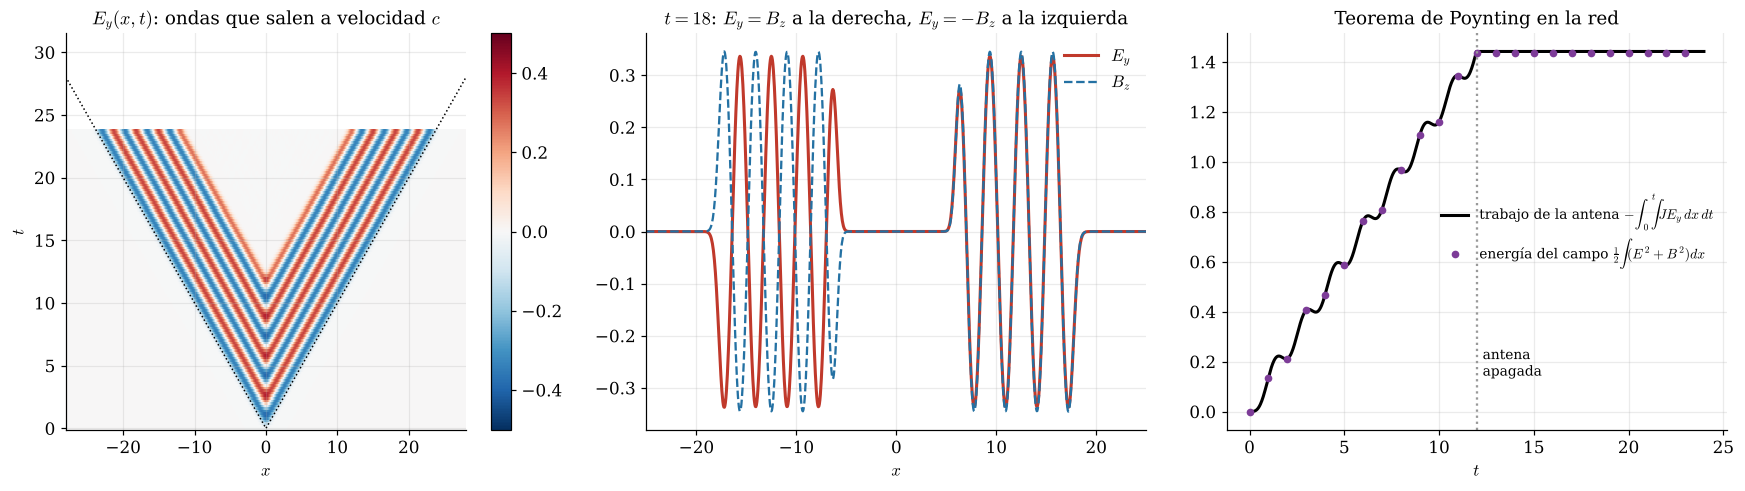

In [7]:
Ey_h = -np.gradient(hist, tiempos, axis=0)
Bz_h = np.gradient(hist, dx, axis=1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
A = ax[0]
im = A.pcolormesh(x, tiempos, Ey_h, cmap='RdBu_r', shading='auto', vmin=-0.5, vmax=0.5)
A.plot(x, np.abs(x), 'k:', lw=1); A.set_xlim(-28, 28)
A.set_xlabel('$x$'); A.set_ylabel('$t$'); A.set_title(r'$E_y(x,t)$: ondas que salen a velocidad $c$')
plt.colorbar(im, ax=A)
A = ax[1]
k = np.argmin(np.abs(tiempos - 18))
A.plot(x, Ey_h[k], color=C['E'], lw=2, label='$E_y$')
A.plot(x, Bz_h[k], color=C['B'], lw=1.5, ls='--', label='$B_z$')
A.set_xlim(-25, 25); A.set_xlabel('$x$'); A.set_title(f'$t={tiempos[k]:.0f}$: $E_y=B_z$ a la derecha, $E_y=-B_z$ a la izquierda')
A.legend()
A = ax[2]
tt = dt*np.arange(Nt)
A.plot(tt, W_fuente, color='k', lw=2, label=r'trabajo de la antena $-\int_0^t\!\!\int J E_y\,dx\,dt$')
A.plot(tt[::40], U_campo[::40], 'o', color=C['S'], ms=4, label=r'energía del campo $\frac{1}{2}\int(E^2+B^2)dx$')
A.axvline(12, color='0.6', ls=':'); A.text(12.3, 0.1*W_fuente[-1], 'antena\napagada', fontsize=9)
A.set_xlabel('$t$'); A.set_title('Teorema de Poynting en la red'); A.legend(fontsize=9)
fig.tight_layout(); u.guardar(fig, 'P11_integrador_variacional_antena'); plt.show()

In [8]:
fig, A = plt.subplots(figsize=(8, 3.6))
lE, = A.plot([], [], color=C['E'], lw=2, label='$E_y$')
lB, = A.plot([], [], color=C['B'], lw=1.5, ls='--', label='$B_z$')
lJ, = A.plot([], [], color='k', lw=1, label=r'$J$ (antena, $\times0.3$)')
A.set_xlim(-28, 28); A.set_ylim(-0.6, 0.6); A.set_xlabel('$x$'); A.legend(loc='upper right', fontsize=9)
ttl = A.set_title('')
fig.tight_layout()
def cuadro(i):
    lE.set_data(x, Ey_h[i]); lB.set_data(x, Bz_h[i]); lJ.set_data(x, 0.3*Jx(tiempos[i]))
    ttl.set_text(f'Ondas generadas por la acción discreta,  $t={tiempos[i]:.1f}$')
    return lE, lB, lJ
anim = animation.FuncAnimation(fig, cuadro, frames=range(0, len(tiempos), 2))
u.guardar_gif(anim, 'P11_animacion_antena_red', fps=20)
plt.close(fig)
# la animación se muestra en la celda siguiente (figuras/P11_animacion_antena_red.gif)

[guardado] figuras/P11_animacion_antena_red.gif  (0.93 MB)


![animación](figuras/P11_animacion_antena_red.gif)

**Sobre el Problema 12(c).** En esta simulación nunca impusimos $\nabla\cdot\mathbf{B}=0$ ni Faraday. Se cumplen solas porque calculamos $E_y=-\partial_ta$ y $B_z=\partial_xa$ desde el potencial. En 1D, Faraday es $\partial_tB_z=-\partial_xE_y$, es decir $\partial_t\partial_xa=\partial_x\partial_ta$: la conmutatividad de las derivadas (de nuevo Bianchi).

---
## Problema 13 — Gauge y conservación local de la carga

### (a, b) Dos potenciales, un solo campo

Para $\mathbf{B}=B\hat{z}$ uniforme, dos elecciones clásicas:

- gauge de Landau, $\mathbf{A}_L=Bx\,\hat{y}$ (el del Problema 6);
- gauge simétrico, $\mathbf{A}_S=\frac B2(-y,x,0)$.

Se relacionan por $\mathbf{A}_S=\mathbf{A}_L+\nabla\chi$ con $\chi=-\frac B2xy$. Los campos vectoriales son muy distintos, pero su rotor (calculado numéricamente) es el mismo.

rotor Landau  : min, max = 0.9999999999999929 1.000000000000007
rotor simétrico: min, max = 0.9999999999999929 1.000000000000007
máx |A_S - (A_L + ∇χ)| = 1.3655743202889425e-14


[guardado] figuras/P13_dos_gauges_mismo_campo.png


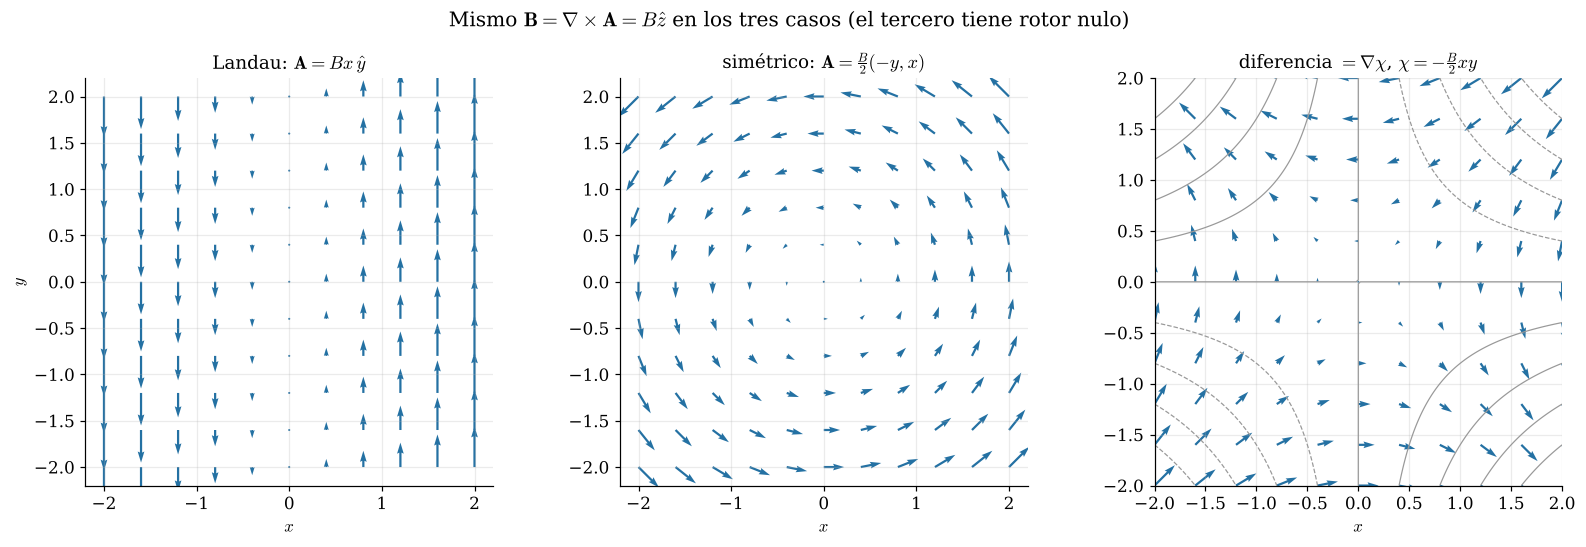

In [9]:
Bv = 1.0
g1 = np.linspace(-2, 2, 201); Xg, Yg = np.meshgrid(g1, g1)
AL = (0*Xg, Bv*Xg); AS = (-Bv*Yg/2, Bv*Xg/2)
chi = -Bv*Xg*Yg/2; gchi = (np.gradient(chi, g1, axis=1), np.gradient(chi, g1, axis=0))
rot = lambda Ax, Ay: np.gradient(Ay, g1, axis=1) - np.gradient(Ax, g1, axis=0)
print("rotor Landau  : min, max =", rot(*AL).min(), rot(*AL).max())
print("rotor simétrico: min, max =", rot(*AS).min(), rot(*AS).max())
print("máx |A_S - (A_L + ∇χ)| =", max(np.abs(AS[0] - AL[0] - gchi[0]).max(), np.abs(AS[1] - AL[1] - gchi[1]).max()))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
s = slice(None, None, 20)
for A, (Ax_, Ay_), tit in [(ax[0], AL, r'Landau: $\mathbf{A}=Bx\,\hat{y}$'),
                           (ax[1], AS, r'simétrico: $\mathbf{A}=\frac{B}{2}(-y,x)$'),
                           (ax[2], gchi, r'diferencia $=\nabla\chi$, $\chi=-\frac{B}{2}xy$')]:
    A.quiver(Xg[s, s], Yg[s, s], Ax_[s, s], Ay_[s, s], color=C['B'], scale=20)
    A.set_aspect('equal'); A.set_title(tit); A.set_xlabel('$x$')
cs = ax[2].contour(Xg, Yg, chi, levels=12, colors='0.6', linewidths=0.8)
ax[0].set_ylabel('$y$')
fig.suptitle(r'Mismo $\mathbf{B}=\nabla\times\mathbf{A}=B\hat{z}$ en los tres casos (el tercero tiene rotor nulo)', y=1.0)
fig.tight_layout(); u.guardar(fig, 'P13_dos_gauges_mismo_campo'); plt.show()

También verificamos simbólicamente el caso general dependiente del tiempo: con $\chi(t,\mathbf{x})$ arbitraria, $A_\mu\to A_\mu-\partial_\mu\chi$ deja $F_{\mu\nu}$ intacto (reutilizamos las expresiones de SymPy de arriba).

In [10]:
chi_s = sp.Function('chi')(*coords)
A_dn_g = sp.Matrix([A_dn[m] - d(m, chi_s) for m in range(4)])
F_dn_g = sp.Matrix(4, 4, lambda m, n: d(m, A_dn_g[n]) - d(n, A_dn_g[m]))
print("F'_{μν} - F_{μν} =", sp.simplify(F_dn_g - F_dn) == sp.zeros(4, 4))
# en lenguaje 3D: A -> A + ∇χ,  φ -> φ - ∂_t χ  equivale a A^μ -> A^μ - ∂^μ χ:
print("A'^μ (3D) == η A'_μ :", sp.simplify(eta*A_dn_g - sp.Matrix([(phi - sp.diff(chi_s, t))/c, *(Avec + grad(chi_s))])) == sp.zeros(4, 1))

F'_{μν} - F_{μν} = True
A'^μ (3D) == η A'_μ : True


### (c) La acción es invariante de gauge **solo si** la carga se conserva

En 1+1 D ($c=1$), el cambio del término de interacción ante $A_\mu\to A_\mu-\partial_\mu\chi$ es

$$\Delta S=\int dt\,dx\;J^\mu\partial_\mu\chi=\underbrace{\int\partial_\mu(J^\mu\chi)}_{\text{frontera}}-\int\chi\,\partial_\mu J^\mu .$$

Con funciones $\chi$ localizadas (nulas en la frontera), calculamos $\Delta S$ numéricamente para el pulso rígido del Problema 5 ($\partial_\mu J^\mu=0$) y para el pulso que "se desvanece" ($\partial_\mu J^\mu=-\rho/\tau$).

In [11]:
tg = np.linspace(0, 10, 801); xg = np.linspace(-6, 14, 1601)
TT, XX = np.meshgrid(tg, xg, indexing='ij')
uu, tau = 0.6, 3.0
rho_ok = np.exp(-(XX - uu*TT)**2); rho_mal = rho_ok*np.exp(-TT/tau)
rng = np.random.default_rng(3)
print("     t0     x0    ΔS (carga conservada)   ΔS (no conservada)   -∫χ ∂μJ^μ (no cons.)")
for _ in range(5):
    t0, x0 = rng.uniform(3, 7), rng.uniform(1, 5)
    chi = np.exp(-((TT - t0)**2 + (XX - x0)**2)/0.8)
    dchi_t = np.gradient(chi, tg, axis=0); dchi_x = np.gradient(chi, xg, axis=1)
    dS = lambda rr: np.trapezoid(np.trapezoid(rr*dchi_t + uu*rr*dchi_x, xg, axis=1), tg)
    pred = -np.trapezoid(np.trapezoid(chi*(-rho_mal/tau), xg, axis=1), tg)
    print(f"   {t0:5.2f}  {x0:5.2f}     {dS(rho_ok):+.2e}              {dS(rho_mal):+.4f}             {pred:+.4f}")

     t0     x0    ΔS (carga conservada)   ΔS (no conservada)   -∫χ ∂μJ^μ (no cons.)
    3.34   1.95     +2.66e-06              +0.1945             +0.1945
    6.21   3.33     +1.67e-05              +0.0715             +0.0715


    3.38   2.73     -2.24e-05              +0.1430             +0.1430


    4.92   1.64     +1.24e-05              +0.0557             +0.0557
    5.94   1.45     -5.03e-06              +0.0114             +0.0114


### (d) El vínculo de Gauss se mantiene solo si $\partial_\mu J^\mu=0$

Las ecuaciones de Maxwell tienen una estructura de "evolución + vínculo". Las de evolución son Ampère–Maxwell y Faraday, que determinan $\partial_t\mathbf{E}$ y $\partial_t\mathbf{B}$. Los vínculos son Gauss y $\nabla\cdot\mathbf{B}=0$, que **no** tienen derivadas temporales. Tomando $\partial_t$ de Gauss y usando Ampère:

$$\partial_t\big(\nabla\cdot\mathbf{E}-\rho/\varepsilon_0\big)=\nabla\cdot\big(c^2\nabla\times\mathbf{B}-\mathbf{J}/\varepsilon_0\big)-\partial_t\rho/\varepsilon_0=-\frac1{\varepsilon_0}\big(\partial_t\rho+\nabla\cdot\mathbf{J}\big).$$

Si la carga se conserva, un $\mathbf{E}$ que cumple Gauss en $t=0$ lo cumple siempre. Es exactamente el argumento del Problema 13(d): $\partial_\nu\partial_\mu F^{\mu\nu}\equiv0$.

**Simulación.** Caso longitudinal en 1D: solo hay $E_x(x,t)$ y Ampère se reduce a $\partial_tE_x=-J_x$ ($\varepsilon_0=1$). Partimos de un $E_x$ que cumple Gauss, evolucionamos **solo con Ampère** y medimos la violación $\mathcal C=\partial_xE_x-\rho$.

[guardado] figuras/P13_vinculo_gauss_conservacion_carga.png


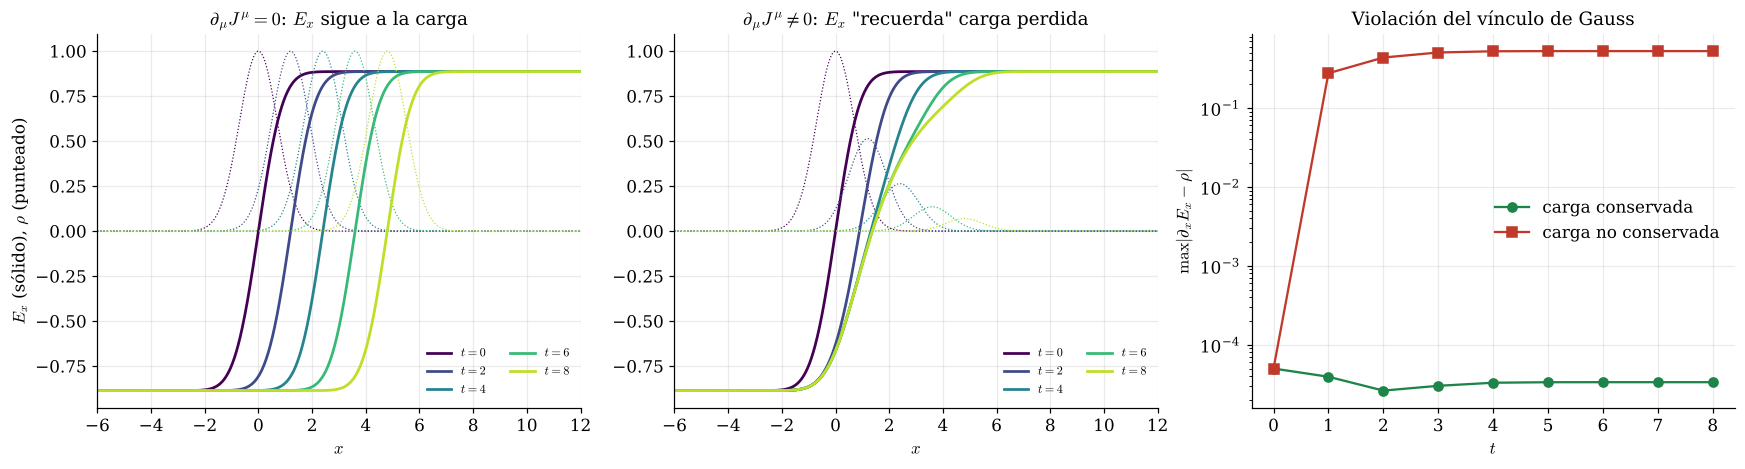

In [12]:
xg = np.linspace(-10, 20, 3001); dxg = xg[1] - xg[0]
dtg = 0.002; tfin = 8.0
def evolucionar(conserva):
    rho_f = (lambda t: np.exp(-(xg - uu*t)**2)) if conserva else (lambda t: np.exp(-(xg - uu*t)**2)*np.exp(-t/tau))
    Jf = lambda t: uu*rho_f(t)
    Ex = cumulative_trapezoid(rho_f(0), xg, initial=0); Ex -= Ex[-1]/2   # cumple Gauss: ∂x E = ρ
    ts, viol, perfiles = [], [], []
    for n in range(int(tfin/dtg) + 1):
        tn = n*dtg
        if n % 500 == 0:
            Cg = np.gradient(Ex, dxg) - rho_f(tn)
            ts.append(tn); viol.append(np.abs(Cg).max()); perfiles.append((tn, Ex.copy(), rho_f(tn)))
        Ex = Ex - dtg*0.5*(Jf(tn) + Jf(tn + dtg))          # Ampère: ∂t E = -J  (regla del trapecio)
    return np.array(ts), np.array(viol), perfiles

t_ok, v_ok, p_ok = evolucionar(True)
t_mal, v_mal, p_mal = evolucionar(False)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for A, perf, tit in [(ax[0], p_ok, r'$\partial_\mu J^\mu=0$: $E_x$ sigue a la carga'),
                     (ax[1], p_mal, r'$\partial_\mu J^\mu\neq0$: $E_x$ "recuerda" carga perdida')]:
    cm = plt.cm.viridis(np.linspace(0, 0.9, len(perf)))
    for (tn, Ex, rr), co in zip(perf[::2], cm[::2]):
        A.plot(xg, Ex, color=co, lw=1.8, label=f'$t={tn:.0f}$')
        A.plot(xg, rr, color=co, lw=0.8, ls=':')
    A.set_xlim(-6, 12); A.set_xlabel('$x$'); A.set_title(tit); A.legend(fontsize=8, ncol=2)
ax[0].set_ylabel(r'$E_x$ (sólido), $\rho$ (punteado)')
A = ax[2]
A.semilogy(t_ok, v_ok + 1e-16, 'o-', color=C['v'], label=r'carga conservada')
A.semilogy(t_mal, v_mal + 1e-16, 's-', color=C['E'], label=r'carga no conservada')
A.set_xlabel('$t$'); A.set_ylabel(r'$\max|\partial_xE_x-\rho|$'); A.set_title('Violación del vínculo de Gauss')
A.legend()
fig.tight_layout(); u.guardar(fig, 'P13_vinculo_gauss_conservacion_carga'); plt.show()

Con carga conservada, la violación queda en el nivel del error de discretización. En el otro caso crece sin cota: el campo "recuerda" una carga que desapareció **sin fluir a ninguna parte**, y Gauss deja de cumplirse. No existe una solución de Maxwell con esas fuentes.

---
## Problema 14 — Gauge de Lorenz, ecuación de onda y Liénard–Wiechert

### El cono de luz pasado

$\Box A^\mu=\mu_0J^\mu$ tiene una solución retardada: el campo en el evento $(t,\mathbf{r})$ depende solo de lo que la carga hizo en el instante $t_r$ en que su línea de mundo **corta el cono de luz pasado** del evento. Para $|\mathbf{v}|<c$ la intersección es única: la función $g(t')=t-t'-|\mathbf{r}-\mathbf{w}(t')|/c$ es estrictamente decreciente, con $g'=-(1-\hat{n}\cdot\boldsymbol\beta)<0$. Por eso la bisección de `em_utils.tiempo_retardado` siempre converge. El factor $(1-\hat{n}\cdot\boldsymbol\beta)$ es el jacobiano que aparece en $\phi_{LW}$.

[guardado] figuras/P14_cono_de_luz_tiempo_retardado.png


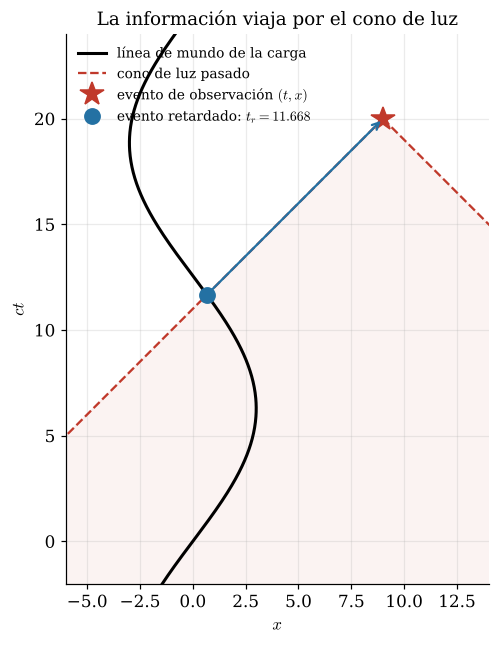

comprobación: t - t_r = 8.331926,   |x - w(t_r)|/c = 8.331926


In [13]:
A0, om = 3.0, 0.25          # oscilación x_q(t) = A0 sin(ωt), β_max = 0.75
wq = lambda tq: np.stack([A0*np.sin(om*np.asarray(tq)), 0*np.asarray(tq), 0*np.asarray(tq)], -1)
t_obs, x_obs = 20.0, 9.0
tr = u.tiempo_retardado(np.array([[x_obs, 0, 0]]), t_obs, wq)[0]
ts = np.linspace(-2, 24, 600)

fig, A = plt.subplots(figsize=(6.5, 6))
A.plot(wq(ts)[:, 0], ts, color='k', lw=2, label='línea de mundo de la carga')
A.plot([x_obs, x_obs - 30], [t_obs, t_obs - 30], color=C['E'], lw=1.5, ls='--', label='cono de luz pasado')
A.plot([x_obs, x_obs + 30], [t_obs, t_obs - 30], color=C['E'], lw=1.5, ls='--')
A.fill_between([x_obs - 30, x_obs, x_obs + 30], [t_obs - 30, t_obs, t_obs - 30], -5, color=C['E'], alpha=0.06)
A.plot(x_obs, t_obs, '*', color=C['E'], ms=16, label='evento de observación $(t,x)$')
A.plot(wq(tr)[0], tr, 'o', color=C['B'], ms=10, label=f'evento retardado: $t_r={tr:.3f}$')
A.annotate('', xy=(x_obs, t_obs), xytext=(wq(tr)[0], tr), arrowprops=dict(arrowstyle='->', color=C['B'], lw=1.5))
A.set_xlim(-6, 14); A.set_ylim(-2, 24); A.set_aspect('equal')
A.set_xlabel('$x$'); A.set_ylabel('$ct$'); A.legend(loc='upper left', fontsize=9)
A.set_title('La información viaja por el cono de luz')
fig.tight_layout(); u.guardar(fig, 'P14_cono_de_luz_tiempo_retardado'); plt.show()
print(f"comprobación: t - t_r = {t_obs - tr:.6f},   |x - w(t_r)|/c = {abs(x_obs - wq(tr)[0]):.6f}")

### Los potenciales de Liénard–Wiechert satisfacen el gauge de Lorenz y la ecuación de onda

Calculamos $\phi_{LW}=\frac{q}{4\pi\varepsilon_0}\frac{1}{R(1-\hat{n}\cdot\boldsymbol\beta)}$ y $\mathbf{A}_{LW}=\boldsymbol\beta\phi_{LW}/c$ en puntos al azar, lejos de la carga, y evaluamos con diferencias finitas centradas:

- la condición de Lorenz, $\frac1{c^2}\partial_t\phi+\nabla\cdot\mathbf{A}$;
- el operador de onda, $\Box\phi=\frac1{c^2}\partial_t^2\phi-\nabla^2\phi$, que debe anularse fuera de la fuente.

In [14]:
vq = lambda tq: np.stack([A0*om*np.cos(om*np.asarray(tq)), 0*np.asarray(tq), 0*np.asarray(tq)], -1)
aq = lambda tq: np.stack([-A0*om**2*np.sin(om*np.asarray(tq)), 0*np.asarray(tq), 0*np.asarray(tq)], -1)
rng = np.random.default_rng(7)
P = rng.uniform(-15, 15, (300, 3)); P = P[np.linalg.norm(P, axis=1) > 6]
t0 = 5.0; h = 1e-3
pot = lambda r, tt: u.potenciales_LW(r, tt, wq, vq)
phi0, A_0 = pot(P, t0)
dphi_dt = (pot(P, t0 + h)[0] - pot(P, t0 - h)[0])/(2*h)
divA = sum((pot(P + h*np.eye(3)[i], t0)[1][:, i] - pot(P - h*np.eye(3)[i], t0)[1][:, i])/(2*h) for i in range(3))
lorenz = dphi_dt + divA
d2t = (pot(P, t0 + h)[0] - 2*phi0 + pot(P, t0 - h)[0])/h**2
lap = sum((pot(P + h*np.eye(3)[i], t0)[0] - 2*phi0 + pot(P - h*np.eye(3)[i], t0)[0])/h**2 for i in range(3))
escala = np.abs(dphi_dt).max()
print(f"max |∂tφ/c² + ∇·A| / max|∂tφ| = {np.abs(lorenz).max()/escala:.1e}   (gauge de Lorenz)")
print(f"max |□φ| / max|∇²φ|           = {np.abs(d2t - lap).max()/np.abs(lap).max():.1e}   (ecuación de onda homogénea fuera de la carga)")

max |∂tφ/c² + ∇·A| / max|∂tφ| = 1.4e-07   (gauge de Lorenz)
max |□φ| / max|∇²φ|           = 2.6e-07   (ecuación de onda homogénea fuera de la carga)


### La espiral de radiación: de dipolo a sincrotrón

Una carga en órbita circular (radio $r_0$, $\omega=1$, $\beta=r_0\omega/c$) en el plano $z=0$. Graficamos la componente azimutal del **campo de aceleración** multiplicada por $R$ (para quitar la caída $1/R$), sobre el plano de la órbita.

- $\beta$ pequeño: espiral suave y sinusoidal. Es la superposición de dos dipolos en cuadratura (Problema 1, caso circular).
- $\beta$ grande ($0.8$): el efecto faro (Problema 4) convierte la espiral en **pulsos estrechos**. El observador recibe un destello por vuelta: es la radiación sincrotrón, rica en armónicos.

[guardado] figuras/P14_espiral_radiacion_LW.png


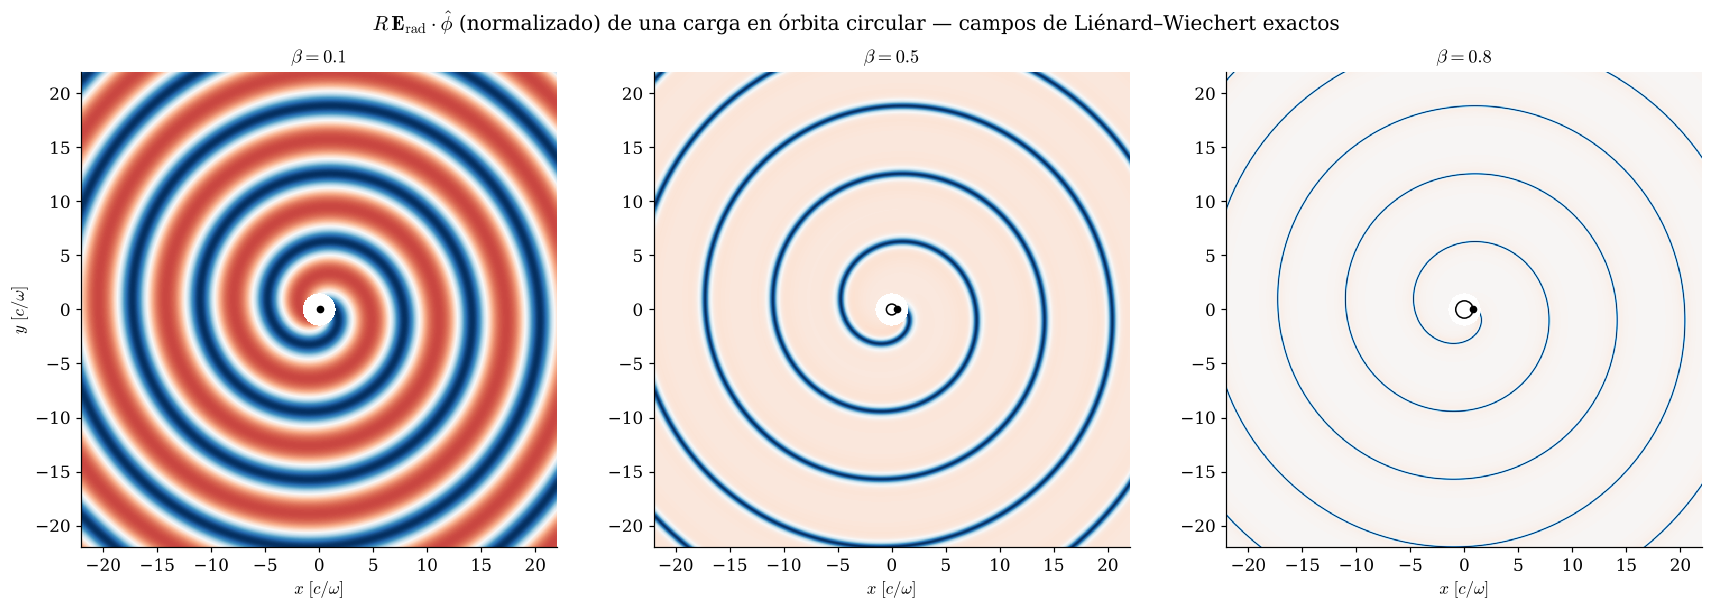

In [15]:
def orbita_circ(beta):
    r0 = beta
    w = lambda tq: np.stack([r0*np.cos(np.asarray(tq)), r0*np.sin(np.asarray(tq)), 0*np.asarray(tq)], -1)
    v = lambda tq: np.stack([-r0*np.sin(np.asarray(tq)), r0*np.cos(np.asarray(tq)), 0*np.asarray(tq)], -1)
    a = lambda tq: -np.stack([r0*np.cos(np.asarray(tq)), r0*np.sin(np.asarray(tq)), 0*np.asarray(tq)], -1)
    return w, v, a

Lg = 22.0; Ng = 320
g1 = np.linspace(-Lg, Lg, Ng); XX, YY = np.meshgrid(g1, g1)
Pg = np.stack([XX, YY, 0*XX], -1)
Rg = np.hypot(XX, YY)
ephi = np.stack([-YY/np.maximum(Rg, 1e-9), XX/np.maximum(Rg, 1e-9), 0*XX], -1)

g2 = np.linspace(-Lg, Lg, 900); XF, YF = np.meshgrid(g2, g2)
PF = np.stack([XF, YF, 0*XF], -1); RF = np.hypot(XF, YF)
ephiF = np.stack([-YF/np.maximum(RF, 1e-9), XF/np.maximum(RF, 1e-9), 0*XF], -1)

def mapa(beta, t, fino=False):
    w, v, a = orbita_circ(beta)
    P_, R_, e_ = (PF, RF, ephiF) if fino else (Pg, Rg, ephi)
    Ev, Er, B, tr = u.campos_LW(P_, t, w, v, a)
    f = np.sum(Er*e_, -1)*R_
    f[R_ < 1.5] = np.nan
    return f/np.nanmax(np.abs(f))

fig, ax = plt.subplots(1, 3, figsize=(16, 5.3))
for A, be in zip(ax, [0.1, 0.5, 0.8]):
    f = mapa(be, 0.0, fino=True)
    A.pcolormesh(XF, YF, f, cmap='RdBu_r', vmin=-1, vmax=1, shading='auto', rasterized=True)
    A.add_patch(plt.Circle((0, 0), be, fill=False, color='k')); A.plot(be, 0, 'ko', ms=4)
    A.set_aspect('equal'); A.grid(False); A.set_title(fr'$\beta={be}$'); A.set_xlabel('$x\\;[c/\\omega]$')
ax[0].set_ylabel('$y\\;[c/\\omega]$')
fig.suptitle(r'$R\,\mathbf{E}_{\rm rad}\cdot\hat{\phi}$ (normalizado) de una carga en órbita circular — campos de Liénard–Wiechert exactos', y=1.0)
fig.tight_layout(); u.guardar(fig, 'P14_espiral_radiacion_LW'); plt.show()

In [16]:
fig, A = plt.subplots(figsize=(5.4, 5.4))
be = 0.6; fr = 36
im = A.pcolormesh(XX, YY, mapa(be, 0.0), cmap='RdBu_r', vmin=-1, vmax=1, shading='auto')
A.add_patch(plt.Circle((0, 0), be, fill=False, color='k'))
pto, = A.plot([], [], 'ko', ms=5)
A.set_aspect('equal'); A.grid(False); A.set_xlabel('$x$'); A.set_ylabel('$y$')
ttl = A.set_title('')
fig.tight_layout()
def cuadro(i):
    tt = 2*np.pi*i/fr
    im.set_array(mapa(be, tt).ravel())
    pto.set_data([be*np.cos(tt)], [be*np.sin(tt)])
    ttl.set_text(fr'Liénard–Wiechert, $\beta={be}$, $\omega t/2\pi={i/fr:.2f}$')
    return im, pto
anim = animation.FuncAnimation(fig, cuadro, frames=fr)
u.guardar_gif(anim, 'P14_animacion_espiral_LW', fps=12, dpi=70)
plt.close(fig)
# la animación se muestra en la celda siguiente (figuras/P14_animacion_espiral_LW.gif)

[guardado] figuras/P14_animacion_espiral_LW.gif  (1.46 MB)


![animación](figuras/P14_animacion_espiral_LW.gif)

### ¿Cuándo vale la fórmula no relativista (3) de la Parte I?

Comparamos el campo de aceleración exacto de Liénard–Wiechert con la fórmula (3), $\mathbf{E}\simeq\frac{q}{4\pi\varepsilon_0c^2R}\hat{n}\times(\hat{n}\times\mathbf{a}(t-R/c))$, para una carga que oscila linealmente con velocidad máxima $\beta_{\max}$, en puntos lejanos. El error relativo debe ir como $\mathcal O(\beta)$. Esa es la precisión de la aproximación usada en los Problemas 1–3.

[guardado] figuras/P14_validez_aproximacion_no_relativista.png


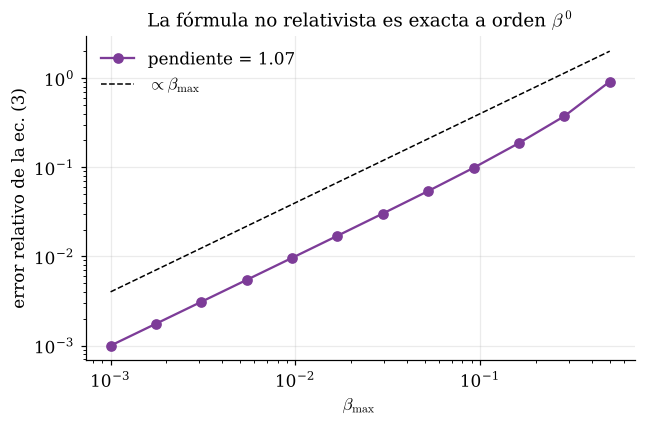

In [17]:
Rfar = 400.0
ang = np.linspace(0.2, np.pi - 0.2, 40)
Pfar = Rfar*np.stack([np.sin(ang), 0*ang, np.cos(ang)], -1)
errs = []
bmaxs = np.logspace(-3, -0.3, 12)
for bm in bmaxs:
    A0l, oml = bm, 1.0
    w = lambda tq: np.stack([0*np.asarray(tq), 0*np.asarray(tq), A0l*np.sin(oml*np.asarray(tq))], -1)
    v = lambda tq: np.stack([0*np.asarray(tq), 0*np.asarray(tq), A0l*oml*np.cos(oml*np.asarray(tq))], -1)
    a = lambda tq: np.stack([0*np.asarray(tq), 0*np.asarray(tq), -A0l*oml**2*np.sin(oml*np.asarray(tq))], -1)
    e_max = 0
    for tt in np.linspace(0, 2*np.pi, 16):
        _, Er, _, _ = u.campos_LW(Pfar, tt, w, v, a)
        n = Pfar/Rfar
        aNR = a(tt - Rfar)
        ENR = np.cross(n, np.cross(n, aNR))/Rfar
        e_max = max(e_max, np.max(np.linalg.norm(Er - ENR, axis=1))/(A0l*oml**2/Rfar))
    errs.append(e_max)
errs = np.array(errs)
pend = np.polyfit(np.log(bmaxs), np.log(errs), 1)[0]
fig, A = plt.subplots(figsize=(6, 4))
A.loglog(bmaxs, errs, 'o-', color=C['S'], label=f'pendiente = {pend:.2f}')
A.loglog(bmaxs, 4*bmaxs, 'k--', lw=1, label=r'$\propto\beta_{\max}$')
A.set_xlabel(r'$\beta_{\max}$'); A.set_ylabel(r'error relativo de la ec. (3)')
A.set_title('La fórmula no relativista es exacta a orden $\\beta^0$'); A.legend()
fig.tight_layout(); u.guardar(fig, 'P14_validez_aproximacion_no_relativista'); plt.show()

El error escala linealmente con $\beta_{\max}$. Proviene de dos fuentes de orden $\beta$: el factor $(1-\hat{n}\cdot\boldsymbol\beta)^{-3}$ y el término $-\boldsymbol\beta$ en $(\hat{n}-\boldsymbol\beta)$, más la corrección $\hat{n}\cdot\mathbf{w}/c$ en el tiempo retardado. Para $\beta\sim10^{-2}$ la fórmula (3) es precisa al por ciento. En el extremo opuesto, la espiral de $\beta=0.9$ muestra que la aproximación falla por completo.